# 01 - Exploração de Dados (EDA) e Pipeline de Pré-processamento
**Tech Challenge - Fase 1 | Sistema de Suporte ao Diagnóstico de Câncer de Mama**

### 1. Contexto Clínico e Definição do Problema
O objetivo deste estudo é construir a base de um sistema inteligente de apoio à triagem médica utilizando o dataset público **Breast Cancer Wisconsin (Diagnostic)**.
- **Variável Alvo (`target`):** Recodificada para o padrão clínico onde `1 = Maligno (Presença da doença)` e `0 = Benigno (Ausência de malignidade)`.
- **Impacto Hospitalar:** Automatizar a análise inicial de parâmetros morfológicos de núcleos celulares (obtidos por Punção Aspirativa por Agulha Fina - PAAF) permite priorizar pacientes de alto risco na fila de patologia e oncologia, reduzindo erros diagnósticos.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath('../src'))
from pipeline import load_and_prepare_data, split_dataset, build_preprocessor

df = load_and_prepare_data()
print(f'Dimensões do Dataset: {df.shape}')
df.head()

Dimensões do Dataset: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1,Maligno
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1,Maligno
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1,Maligno
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1,Maligno
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1,Maligno


### 2. Inspeção de Tipos, Valores Ausentes e Estatísticas Descritivas

In [5]:
print('Valores ausentes por coluna:', df.isnull().sum().sum())
print('\nDistribuição das classes:')
print(df['diagnostico'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')
df.describe().T.head(12)

Valores ausentes por coluna: 0

Distribuição das classes:
diagnostico
Benigno    62.74%
Maligno    37.26%
Name: proportion, dtype: str


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


### 3. Visualização de Distribuições e Matriz de Correlação
Analisamos a separabilidade das classes e a colinearidade entre atributos geométricos (`radius`, `perimeter`, `area`, `concavity`).

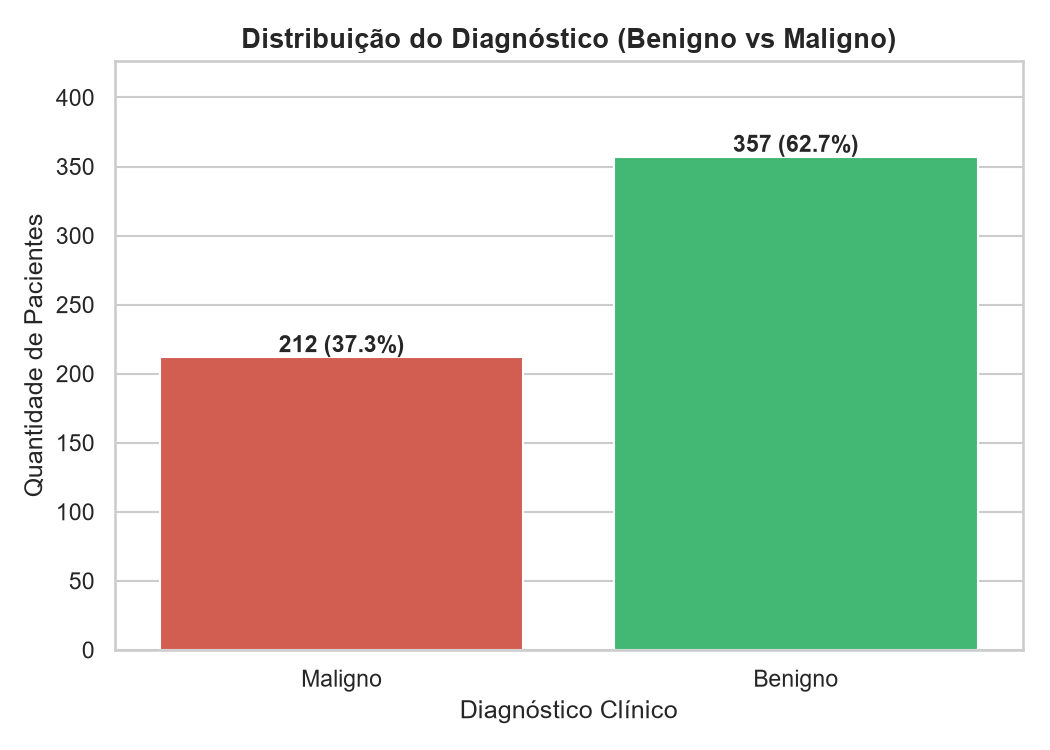

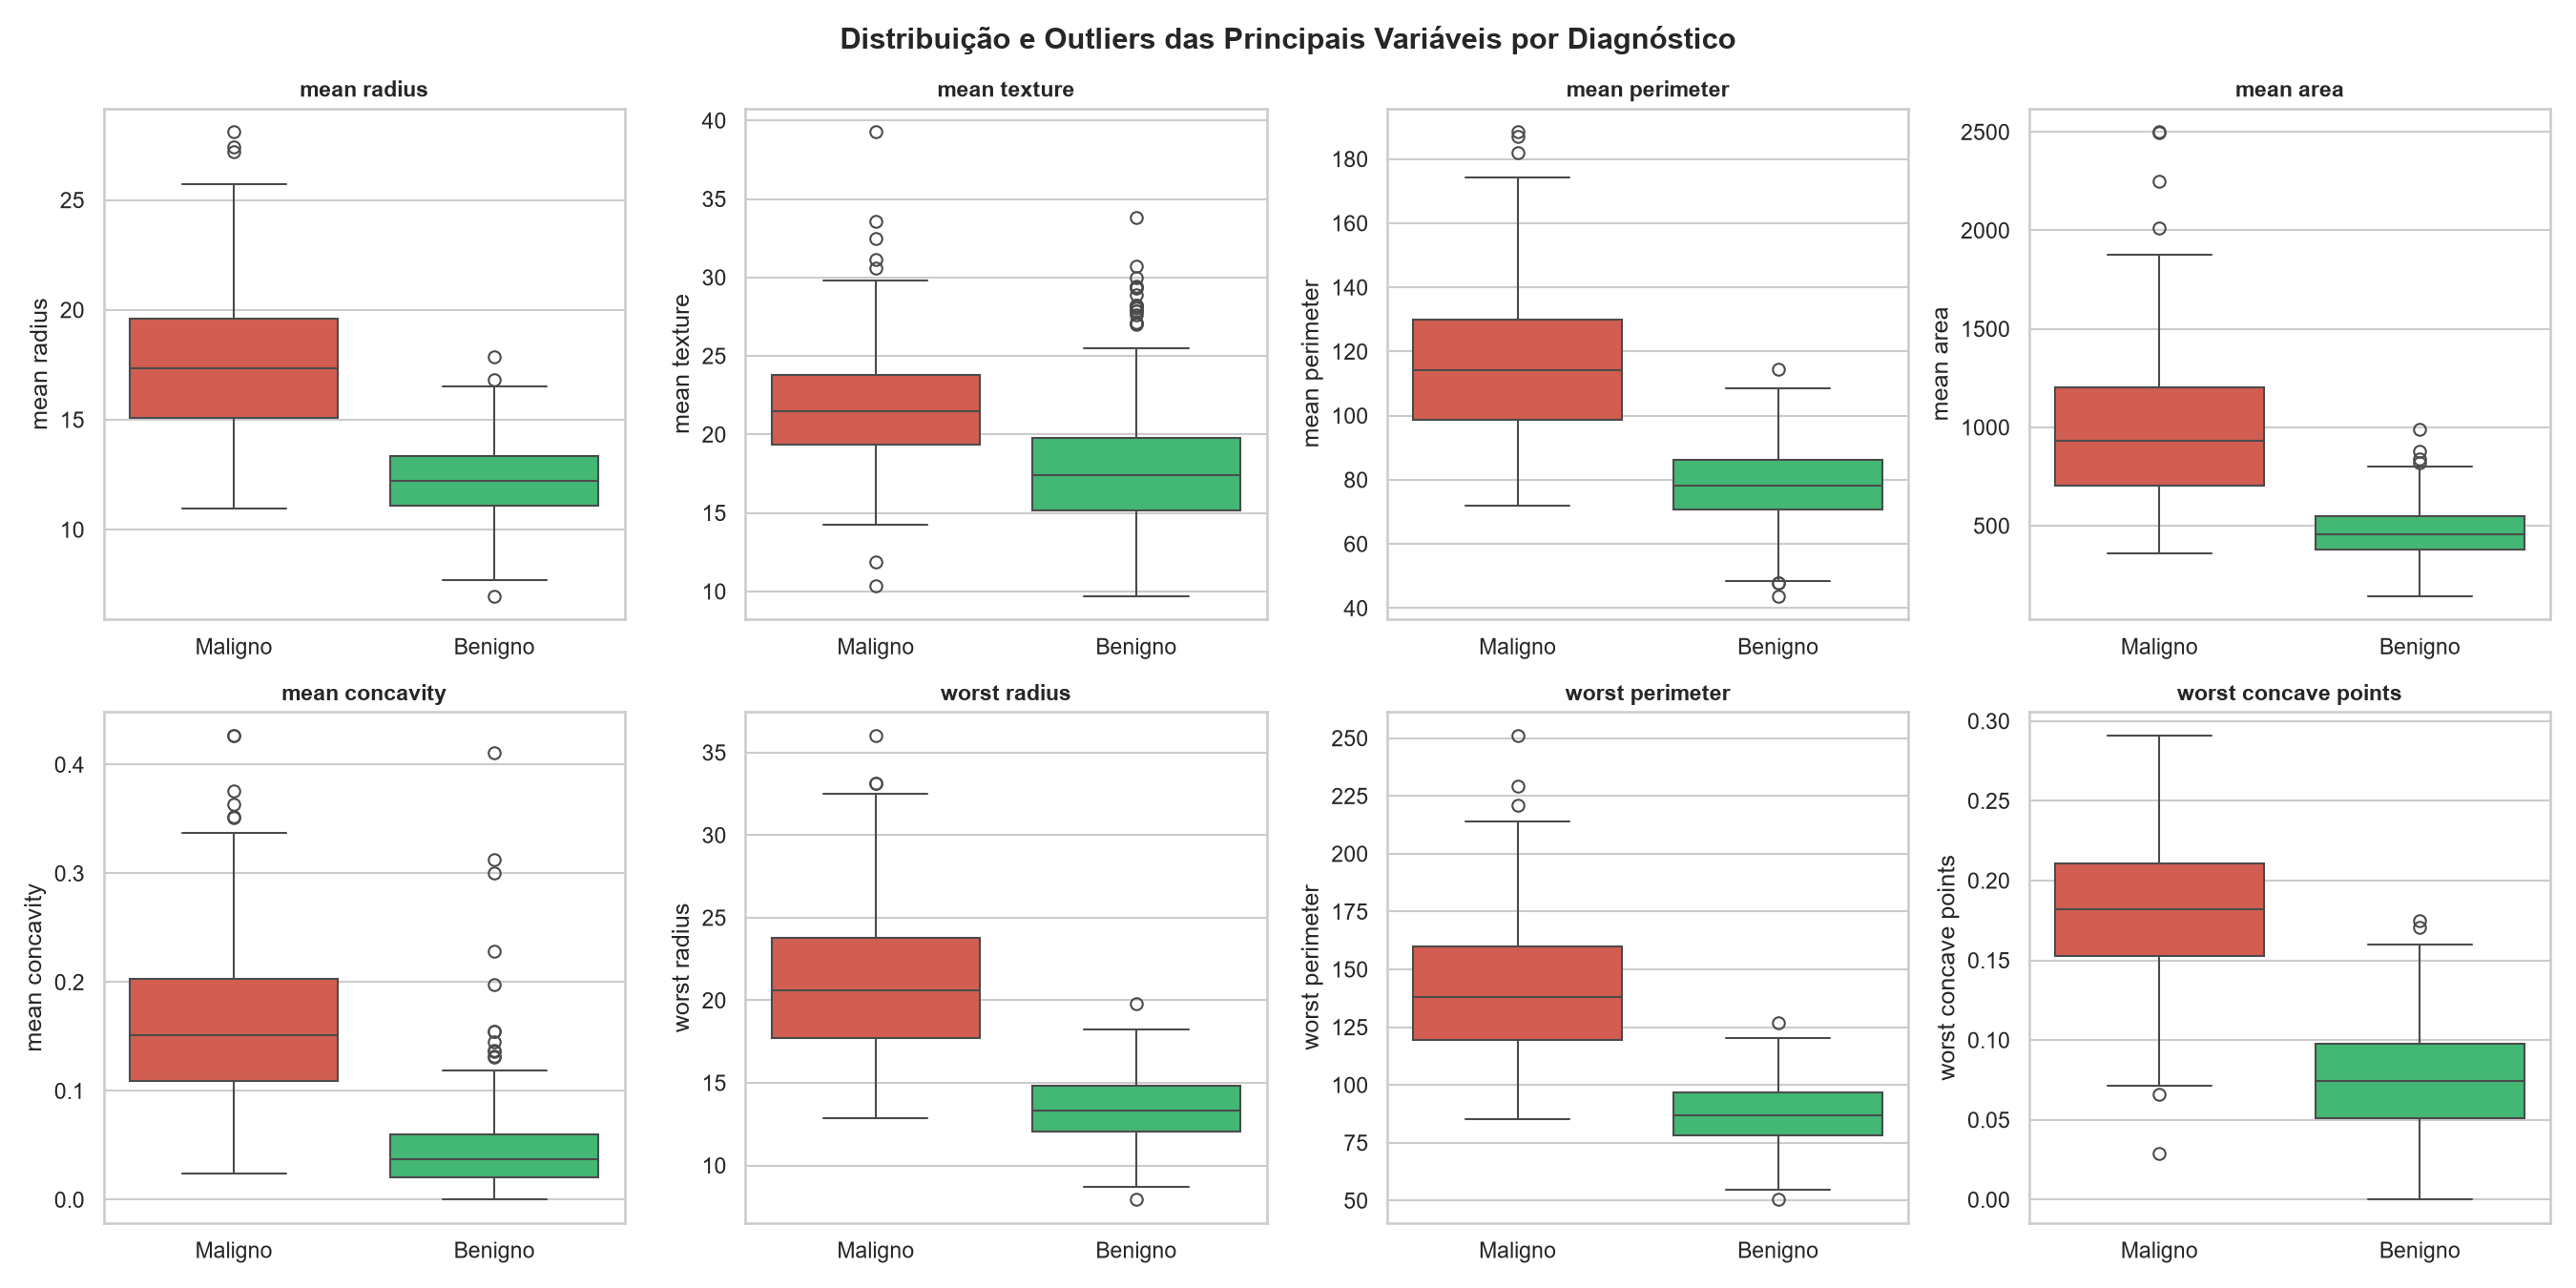

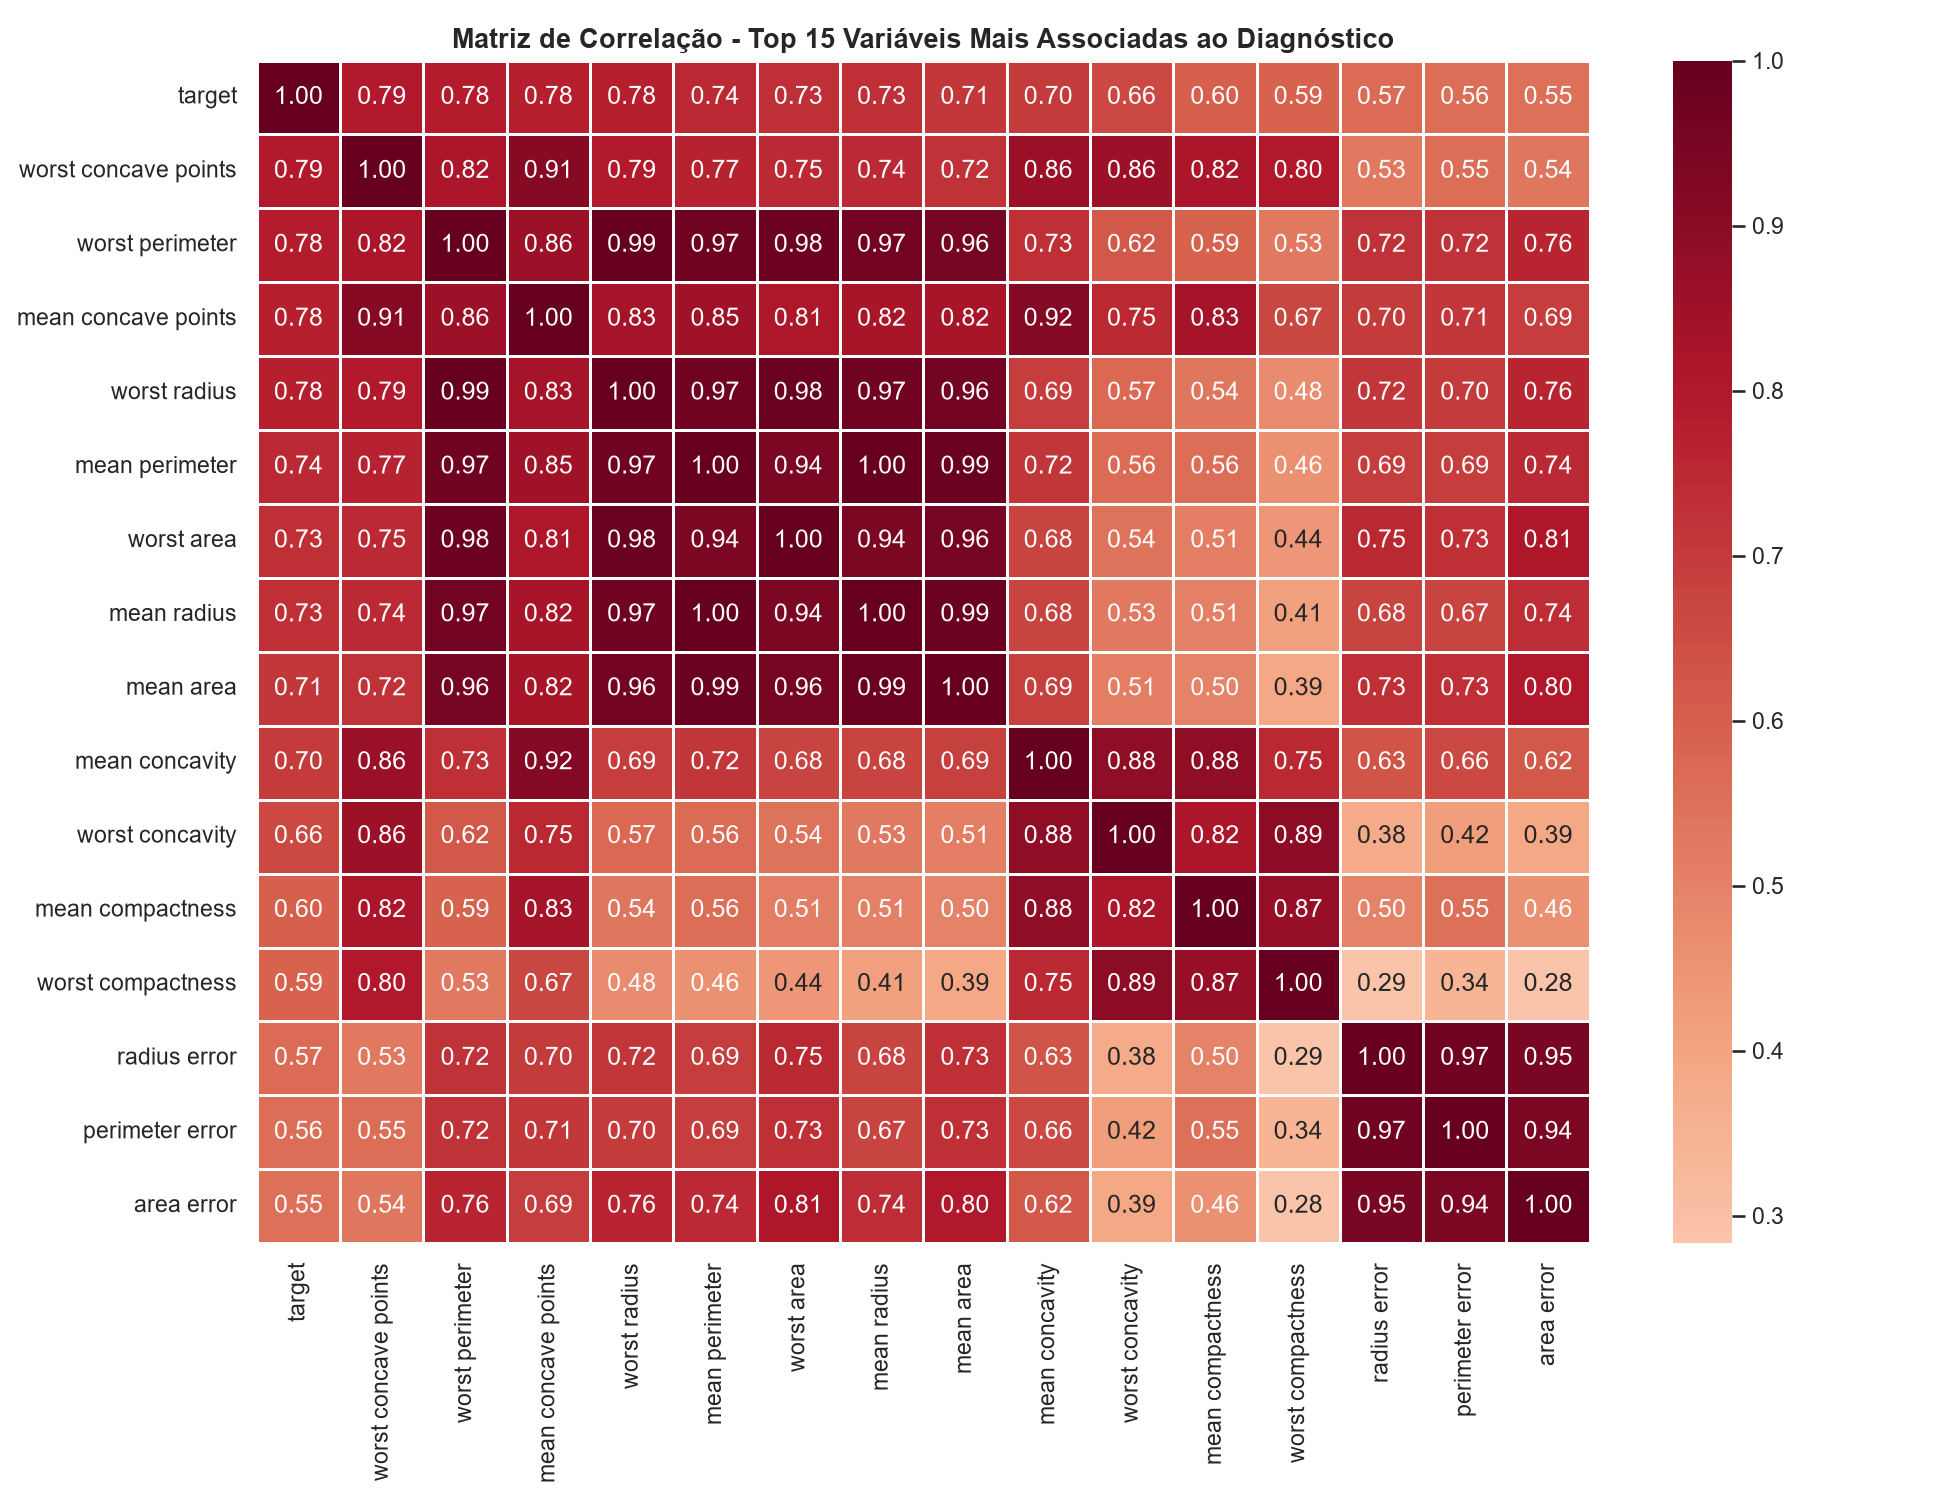

In [6]:
from IPython.display import Image, display
display(Image('../reports/figures/01_distribuicao_classes.png'))
display(Image('../reports/figures/02_boxplots_principais_variaveis.png'))
display(Image('../reports/figures/03_matriz_correlacao.png'))

### 4. Divisão Estratificada (Treino 70% / Validação 15% / Teste 15%) e Pipeline sem Data Leakage
A separação ocorre **antes** de qualquer cálculo de mediana (`SimpleImputer`) ou padronização (`StandardScaler`).

In [7]:
X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(df)
print(f'Treino: {X_train.shape} | Validação: {X_val.shape} | Teste: {X_test.shape}')

preprocessor = build_preprocessor()
X_train_processed = preprocessor.fit_transform(X_train)
print('Pipeline ajustado com sucesso no conjunto de treino!')

Treino: (398, 30) | Validação: (85, 30) | Teste: (86, 30)
Pipeline ajustado com sucesso no conjunto de treino!
